# Privacy Leakage in Machine Learning: Membership Inference Attacks, Defenses, and Disparate Vulnerability
---

### In one paragraph
A neural network behaves slightly differently on the data it was trained on than on data it has never seen. An attacker can exploit that difference to decide whether a *specific record* was in the training set (a **membership inference attack**). If the training data is medical or financial, that alone is a privacy breach. This notebook (1) builds and measures such attacks, (2) shows *why* they work (overfitting), (3) tests seven defenses including differential privacy, and (4) asks a fairness-style question that is the novel part of the project: **is the privacy risk the same for everyone, or are some groups exposed more than others?**


## How to run this notebook
1. Install PyTorch with CUDA support first (see Section 1). Everything else installs from the next cell.
2. Choose the `.venv` kernel and use **Run All**. Every expensive training step is **cached** in the `artifacts/` folder. The first run trains many models (expect tens of minutes on a GPU); later runs just load them and take a few minutes, mostly for the bootstrap and permutation tests in Section 9.
3. If you change `CONFIG` (dataset size, epochs, seed), the cache filenames change automatically (see the `tag`), so stale models are never reused.
4. Optional extension cells are switched off by default. Set `RUN_OPTIONAL = True` in the config cell to run them.

> **How to read the numbers:** all figures quoted in the markdown come from the author's run on one RTX 4070 with fixed seeds. GPU arithmetic is not perfectly deterministic, so a rerun may differ in the third decimal place; the conclusions should not change.

---
# 1. Setup

### 1.1 Install libraries
**Install PyTorch with CUDA first** (once, outside this notebook, from the PyTorch website). For an RTX 4070 whose driver reports CUDA 12.9, the CUDA 12.6 build works:


In [1]:
# PyTorch (CUDA build) must already be installed. --no-deps stops pip from replacing it with a CPU-only build.
%pip install -q --no-deps opacus
%pip install -q opt-einsum scikit-learn matplotlib pandas scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1.2 Imports, random seed, and configuration

In [2]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.ensemble import GradientBoostingClassifier

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

CONFIG = {
    'N': 2500,          # samples per data group (members, non-members, shadow members, shadow non-members)
    'epochs': 30,       # training epochs of the target model (long enough to overfit)
    'lr': 1e-3,         # learning rate (Adam optimizer)
    'batch_size': 64,
    'seed': 0,          # master random seed
    'augment': False,   # baseline = no augmentation; switched on only for the augmentation defense
}
RUN_OPTIONAL = False    # True = also run the optional extension cells (Section 8.6)

set_seed(CONFIG['seed'])
print(CONFIG)

Using device: cuda
{'N': 2500, 'epochs': 30, 'lr': 0.001, 'batch_size': 64, 'seed': 0, 'augment': False}


### 1.3 GPU check
Confirms PyTorch was built with CUDA and sees the GPU. Expected: a version ending in `+cu126`, `True`, and the GPU name. If it says `+cpu` or `False`, reinstall the CUDA build of PyTorch (Section 1.1) and restart the kernel.

In [3]:
import torch
print(torch.__version__, torch.version.cuda)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

2.14.0+cu126 12.6
True
NVIDIA GeForce RTX 4070 Laptop GPU


---
# 2. Data: members vs. non-members

**Dataset:** CIFAR-10 (60,000 colour images of 32x32 pixels, 10 classes). The first run downloads about 170 MB.

**Key concept.** The attacker's task is to decide whether an image was used to train the model.
- **Members** = images the target model is trained on.
- **Non-members** = images from the same distribution that the target never sees.

To test attacks fairly, we need clean, non-overlapping groups.

### 2.1 Download and convert to tensors
Pixels are normalised from [0, 1] to [-1, 1] (this makes training more stable). The whole dataset is held in memory as two tensors (images, labels), which is fast because CIFAR-10 is small.

In [4]:
N = CONFIG['N']

tfm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_ds = datasets.CIFAR10('./data', train=True,  download=True, transform=tfm)
test_ds  = datasets.CIFAR10('./data', train=False, download=True, transform=tfm)

def to_tensors(ds):
    loader = DataLoader(ds, batch_size=5000)
    xs, ys = zip(*[(x, y) for x, y in loader])
    return torch.cat(xs), torch.cat(ys)

X_all, y_all   = to_tensors(train_ds)
X_test, y_test = to_tensors(test_ds)
class_names = train_ds.classes

print('Train pool:', X_all.shape, '| Test set:', X_test.shape)
print('Classes:', class_names)

Train pool: torch.Size([50000, 3, 32, 32]) | Test set: torch.Size([10000, 3, 32, 32])
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### 2.2 Build four disjoint groups
We shuffle once with a fixed seed and cut the shuffled pool into four groups of `N` images each:

| Group | Used for |
|---|---|
| `X_mem` | **target members**: the target model trains on these |
| `X_non` | **target non-members**: never seen by the target; used to score attacks |
| `X_smem` | **shadow members**: the attacker trains their own *shadow* model on these (Section 6) |
| `X_snon` | **shadow non-members**: the attacker's own known non-members |

The official CIFAR-10 test set (`X_test`) is kept separate and is only used to measure normal accuracy (utility).

The `assert` is a safety check: if even one image appeared in two groups, the attack results would be meaningless.

In [5]:
g = torch.Generator().manual_seed(CONFIG['seed'])
idx = torch.randperm(len(X_all), generator=g)
def grab(a, b):
    return X_all[idx[a:b]], y_all[idx[a:b]]
X_mem,  y_mem  = grab(0,     N)    
X_non,  y_non  = grab(N,   2*N)      
X_smem, y_smem = grab(2*N, 3*N)      
X_snon, y_snon = grab(3*N, 4*N)      
all_ids = torch.cat([idx[0:N], idx[N:2*N], idx[2*N:3*N], idx[3*N:4*N]])
assert len(all_ids.unique()) == len(all_ids), 'Groups overlap!'
print('Groups are disjoint | sizes:', X_mem.shape[0], X_non.shape[0], X_smem.shape[0], X_snon.shape[0])

Groups are disjoint | sizes: 2500 2500 2500 2500


### 2.3 Look at the data

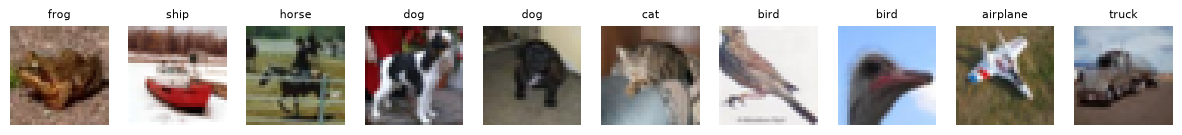

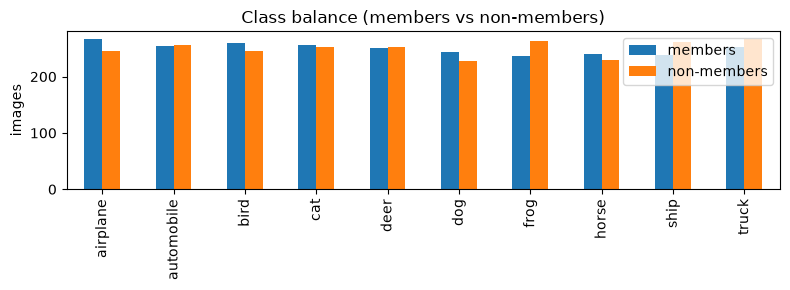

In [6]:
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow((X_mem[i] * 0.5 + 0.5).permute(1, 2, 0).numpy())   # undo the normalisation for display
    ax.set_title(class_names[y_mem[i]], fontsize=8); ax.axis('off')
plt.show()

counts = pd.DataFrame({
    'members':     np.bincount(y_mem.numpy(), minlength=10),
    'non-members': np.bincount(y_non.numpy(), minlength=10),
}, index=class_names)
counts.plot(kind='bar', figsize=(8, 3), title='Class balance (members vs non-members)')
plt.ylabel('images'); plt.tight_layout(); plt.show()

### 2.4 Copy the training groups to the GPU
Training groups are small (2,500 images), so they fit easily in GPU memory. Training is much faster when batches do not have to be copied from the CPU at every step. We keep the CPU copies too, because evaluation and plotting code needs them.

In [7]:
X_mem_gpu,  y_mem_gpu  = X_mem.to(device),  y_mem.to(device)
X_smem_gpu, y_smem_gpu = X_smem.to(device), y_smem.to(device)
print('Training data lives on:', X_mem_gpu.device)

Training data lives on: cuda:0


---
# 3. Building blocks

Everything later reuses these pieces: a cache, a model, a training loop, data augmentation, and the function that extracts what an attacker can observe.

### 3.1 Cache helpers (so you never retrain by accident)
Training the models is the slow part. These helpers save models and results into an `artifacts/` folder and load them on the next run. A training cell always follows the same pattern: *try to load; train only if nothing was saved*.

In [8]:
import os, pickle
os.makedirs('artifacts', exist_ok=True)

def save_model(model, name):
    torch.save(model.state_dict(), f'artifacts/{name}.pt')

def load_model_if_exists(model, name):
    path = f'artifacts/{name}.pt'
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=device))
        return True
    return False

def save_obj(obj, name):
    with open(f'artifacts/{name}.pkl', 'wb') as f:
        pickle.dump(obj, f)

def load_obj(name, default=None):
    path = f'artifacts/{name}.pkl'
    if os.path.exists(path):
        with open(path, 'rb') as f:
            return pickle.load(f)
    return default

### 3.2 The model: a small CNN
Three convolution layers (they learn visual features) followed by two fully connected layers (they turn features into 10 class scores). It has about 620,000 parameters, which is deliberately more than enough to memorize 2,500 images.

It has **no BatchNorm** on purpose: the differential-privacy library (Opacus) does not support it. The `dropout` argument is used by one of the defenses later.

In [9]:
class SmallCNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.c1  = nn.Conv2d(3, 32, 3, padding=1)     # 3 colour channels -> 32 feature maps
        self.c2  = nn.Conv2d(32, 64, 3, padding=1)
        self.c3  = nn.Conv2d(64, 128, 3, padding=1)
        self.fc1 = nn.Linear(128 * 4 * 4, 256)        # 32x32 image halved 3 times -> 4x4
        self.fc2 = nn.Linear(256, 10)                 # 10 class scores
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        x = F.max_pool2d(F.relu(self.c3(x)), 2)
        x = x.flatten(1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)                            # raw scores (logits)

m = SmallCNN().to(device)
print('Parameters:', sum(p.numel() for p in m.parameters()))

Parameters: 620362


### 3.3 Data augmentation function
Randomly flips and shifts images during training so the model cannot memorize exact pixels. It is **off** for the baseline and **on** for the augmentation defense (Section 8). Defined here because the training loop below calls it.

In [10]:
def augment_batch(x):
    # random horizontal flip + random crop (pad 4, cut 32x32), applied per image
    B, C, H, W = x.shape
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)

    padded = F.pad(x, (4, 4, 4, 4), mode='reflect')
    iy = torch.randint(0, 9, (B,), device=x.device)
    ix = torch.randint(0, 9, (B,), device=x.device)
    rows = iy[:, None] + torch.arange(H, device=x.device)
    cols = ix[:, None] + torch.arange(W, device=x.device)
    b = torch.arange(B, device=x.device)[:, None, None, None]
    c = torch.arange(C, device=x.device)[None, :, None, None]
    return padded[b, c, rows[:, None, :, None], cols[:, None, None, :]]

# quick check: shape must be unchanged
print('shape unchanged:', augment_batch(X_mem_gpu[:8]).shape == X_mem_gpu[:8].shape)

shape unchanged: True


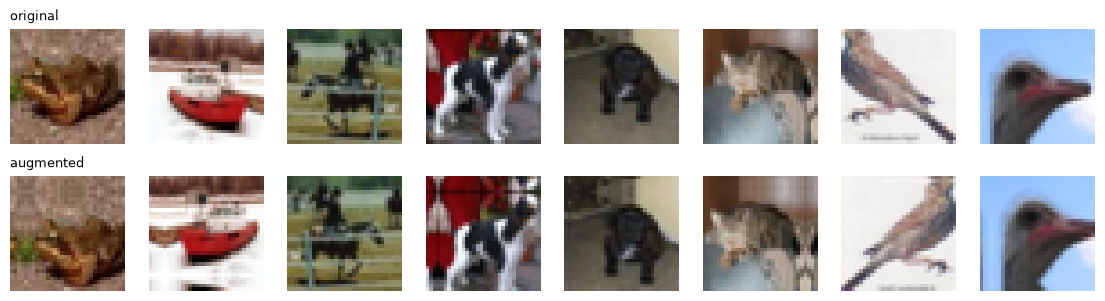

In [11]:
# Visual check: top row = original images, bottom row = augmented versions of the same images
sample = X_mem_gpu[:8]
aug = augment_batch(sample)
fig, axes = plt.subplots(2, 8, figsize=(14, 3.5))
for i in range(8):
    axes[0, i].imshow((sample[i].cpu() * 0.5 + 0.5).permute(1, 2, 0)); axes[0, i].axis('off')
    axes[1, i].imshow((aug[i].cpu() * 0.5 + 0.5).permute(1, 2, 0));    axes[1, i].axis('off')
axes[0, 0].set_title('original', fontsize=9, loc='left'); axes[1, 0].set_title('augmented', fontsize=9, loc='left')
plt.show()

### 3.4 Training loop
One function trains every model in this project. Its arguments are the **defense knobs** used in Section 8:
- `wd`: weight decay (regularization)
- `ls`: label smoothing
- `augment`: data augmentation
- `snapshots` + `callback`: lets us pause at chosen epochs and measure the model (used in Section 7)

Data is batched manually from GPU tensors, which avoids `DataLoader` overhead.

In [12]:
def batches(X, y, bs, shuffle=True):
    # manual batching: X and y already live on the GPU, so no DataLoader overhead
    perm = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        j = perm[i:i + bs]
        yield X[j], y[j]

def train_model(model, X, y, epochs, lr=1e-3, wd=0.0, ls=0.0, augment=False,
                bs=64, snapshots=(), callback=None):
    opt  = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    crit = nn.CrossEntropyLoss(label_smoothing=ls)
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        total, count = 0.0, 0
        for xb, yb in batches(X, y, bs):
            if augment:
                xb = augment_batch(xb)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb); count += len(xb)
        history.append(total / count)
        if callback is not None and epoch in snapshots:
            callback(epoch, model)
    return model, history

### 3.5 What the attacker can see: `get_signals`
For any set of images, this returns what an attacker can observe or compute from the model's output:

| Signal | Meaning |
|---|---|
| `probs` | the full probability vector |
| `conf` | highest probability (how sure the model is) |
| `loss` | cross-entropy loss on the **true** label (low loss = the model fits this sample very well) |
| `margin` | logit margin, `log(p_true / (1 - p_true))` |
| `correct` | was the prediction right? |

Calculations are done in float64 with `log_softmax`, so samples the model is extremely sure about still get slightly different, comparable scores instead of all collapsing to exactly 0.

> **Note.** `margin` and `loss` are both monotonic functions of the true-class probability, so a *global-threshold* attack ranks samples identically with either (their AUCs are always equal in the tables below). Margin only becomes more useful in per-example attacks such as LiRA. We keep it for completeness and to demonstrate this equivalence.

In [13]:
@torch.no_grad()
def get_signals(model, X, y):
    model.eval()
    logits = torch.cat([model(X[i:i+1000].to(device)).cpu() for i in range(0, len(X), 1000)]).double()
    y = y.cpu()
    idx_ = torch.arange(len(y))

    logp   = F.log_softmax(logits, dim=1)
    probs  = logp.exp()
    loss   = -logp[idx_, y]                                   # numerically stable cross-entropy

    # logit margin = log( p_true / (1 - p_true) ), computed without saturating
    others = logits.clone()
    others[idx_, y] = float('-inf')
    margin = logits[idx_, y] - torch.logsumexp(others, dim=1)

    return {
        'probs':   probs.numpy(),                              # full probability vector
        'conf':    probs.max(1).values.numpy(),                # how sure the model is
        'loss':    loss.numpy(),                               # loss on the true label
        'margin':  margin.numpy(),                             # logit margin
        'correct': (probs.argmax(1) == y).numpy(),             # was the prediction right?
    }

def accuracy(model, X, y):
    return get_signals(model, X, y)['correct'].mean()

### 3.6 Sanity test
Before trusting the pipeline, check three things: an untrained model scores about 10% (random guessing among 10 classes), one epoch of training lifts accuracy to roughly 25-35%, and `get_signals` returns one value per image. Expected on your machine: one epoch takes about a second.

In [14]:
import time
set_seed(0)
test_model = SmallCNN().to(device)

print('Untrained accuracy (expect ~0.10):', round(accuracy(test_model, X_test, y_test), 3))

t0 = time.time()
test_model, hist = train_model(test_model, X_mem_gpu, y_mem_gpu, epochs=1)
print(f'1 epoch took {time.time()-t0:.1f}s | loss {hist[0]:.3f}')
print('Accuracy after 1 epoch (expect ~0.25-0.35):', round(accuracy(test_model, X_test, y_test), 3))

s = get_signals(test_model, X_non, y_non)
print({k: v.shape for k, v in s.items()})

Untrained accuracy (expect ~0.10): 0.098
1 epoch took 0.4s | loss 2.117
Accuracy after 1 epoch (expect ~0.25-0.35): 0.286
{'probs': (2500, 10), 'conf': (2500,), 'loss': (2500,), 'margin': (2500,), 'correct': (2500,)}


---
# 4. Train the target (victim) model

The target is trained **only on the 2,500 members**, for 30 epochs, with **no regularization**. It will memorize its training set. That memorization is the raw material of every attack in this notebook.

The cell records accuracy on members, non-members, and the test set after *every* epoch, then saves the model and the curves. On later runs it simply loads them.

In [15]:
tag  = f"N{CONFIG['N']}_ep{CONFIG['epochs']}_seed{CONFIG['seed']}_aug{int(CONFIG['augment'])}"
name = f'target_baseline_{tag}'

target = SmallCNN().to(device)
curves = load_obj(f'curves_{tag}')

if load_model_if_exists(target, name) and curves is not None:
    print('Loaded saved target model, skipping training')
else:
    print('Training target model...')
    set_seed(CONFIG['seed'])
    target = SmallCNN().to(device)
    curves = {'epoch': [], 'train_acc': [], 'nonmember_acc': [], 'test_acc': []}

    def log_epoch(epoch, model):
        curves['epoch'].append(epoch)
        curves['train_acc'].append(accuracy(model, X_mem, y_mem))
        curves['nonmember_acc'].append(accuracy(model, X_non, y_non))
        curves['test_acc'].append(accuracy(model, X_test, y_test))

    E = CONFIG['epochs']
    target, hist = train_model(target, X_mem_gpu, y_mem_gpu, epochs=E,
                               lr=CONFIG['lr'], bs=CONFIG['batch_size'],
                               augment=CONFIG['augment'],
                               snapshots=range(1, E + 1), callback=log_epoch)
    curves['train_loss'] = hist
    save_model(target, name)
    save_obj(curves, f'curves_{tag}')
    print('Saved to artifacts/')

Loaded saved target model, skipping training


### 4.1 Learning and overfitting curves
**Left:** training loss should fall steadily toward zero (the model is fitting its members).
**Right:** member accuracy climbs to 100% while non-member and test accuracy flatten at roughly 50 to 55%. The distance between the curves is the **generalization gap**, the quantity the attack exploits.

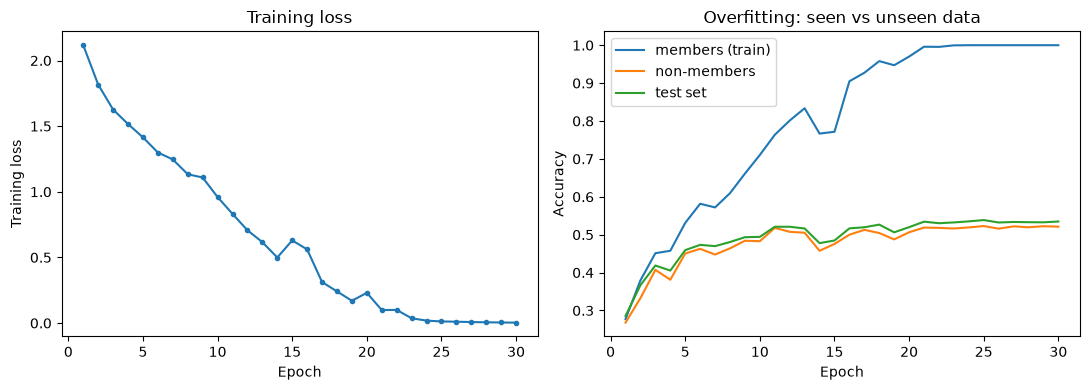

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(curves['epoch'], curves['train_loss'], 'o-', ms=3)
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Training loss'); ax[0].set_title('Training loss')

ax[1].plot(curves['epoch'], curves['train_acc'],     label='members (train)')
ax[1].plot(curves['epoch'], curves['nonmember_acc'], label='non-members')
ax[1].plot(curves['epoch'], curves['test_acc'],      label='test set')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy'); ax[1].set_title('Overfitting: seen vs unseen data')
ax[1].legend()

plt.tight_layout(); plt.show()

### 4.2 The attack signal in numbers
Members should show **higher confidence and lower loss** than non-members. That systematic difference is exactly what the attacks measure. The generalization gap (train accuracy minus test accuracy) summarises the overfitting in one number; here it is about 0.46.

In [17]:
sig_mem = get_signals(target, X_mem, y_mem)
sig_non = get_signals(target, X_non, y_non)
te_acc  = accuracy(target, X_test, y_test)

summary = pd.DataFrame({
    'accuracy':        [sig_mem['correct'].mean(), sig_non['correct'].mean(), te_acc],
    'mean confidence': [sig_mem['conf'].mean(),    sig_non['conf'].mean(),    np.nan],
    'mean loss':       [sig_mem['loss'].mean(),    sig_non['loss'].mean(),    np.nan],
}, index=['members', 'non-members', 'test set'])
display(summary.round(3))

print(f"Generalization gap (train acc - test acc): {sig_mem['correct'].mean() - te_acc:.3f}")

,accuracy,mean confidence,mean loss
members,1.000,0.997,0.003
non-members,0.521,0.880,3.228
test set,0.535,NaN,NaN


Generalization gap (train acc - test acc): 0.465


---
# 5. Threshold attacks (confidence, loss, entropy)

**Idea.** An overfit model is more sure of itself on data it has seen. So the attacker assigns each image a score and says "member" if the score is high. No training of an attack model is needed; only a threshold.

| Attack | Score | Needs |
|---|---|---|
| Confidence | highest predicted probability | model output only |
| Loss | negative loss on the true label | output + true label (stronger) |
| Entropy | negative entropy of the output vector | model output only |

### 5.1 How an attack is scored
`attack_metrics` takes the scores of real members and real non-members and reports:

| Metric | Meaning | Random guessing |
|---|---|---|
| **AUC** | probability that a random member scores higher than a random non-member | 0.5 |
| **Best accuracy** | balanced accuracy at the best threshold | 0.5 |
| **TPR @ 1% FPR** | of all real members, how many are caught while wrongly accusing only 1% of non-members | 0.01 |
| **TPR @ 0.1% FPR** | the same at an even stricter false-alarm rate | 0.001 |

The last two are the metrics modern papers prefer. An average-case AUC can hide that an attacker is *very* sure about a few individuals, and that is a real privacy harm.

In [18]:
def attack_metrics(score_mem, score_non):
    # higher score = "more likely a member"
    scores = np.concatenate([score_mem, score_non])
    labels = np.concatenate([np.ones(len(score_mem)), np.zeros(len(score_non))])
    fpr, tpr, thr = roc_curve(labels, scores)
    return {
        'auc':       roc_auc_score(labels, scores),
        'best_acc':  np.max(0.5 * (tpr + 1 - fpr)),       # balanced accuracy at the best threshold
        'tpr@1%fpr': np.interp(0.01, fpr, tpr),
        'tpr@0.1%fpr': np.interp(0.001, fpr, tpr),
        'fpr': fpr, 'tpr': tpr,
    }

### 5.2 Do members and non-members look different?
If the two histograms barely overlap, the attack will work well. Here they overlap partly. **Members** pile up at confidence 1.0 and at very low loss (the bar at the far left of the loss plot is members the model fits essentially perfectly). **Non-members** are mostly less confident and have higher loss, which is what the attack exploits. But look closely at the confidence plot: a large share of the *non-members* (the orange bar near 1.0 holds on the order of 1,200 of the 2,500) are also classified with near-certainty. A single threshold cannot separate those from memorized members, and this matters for the low-FPR results below.

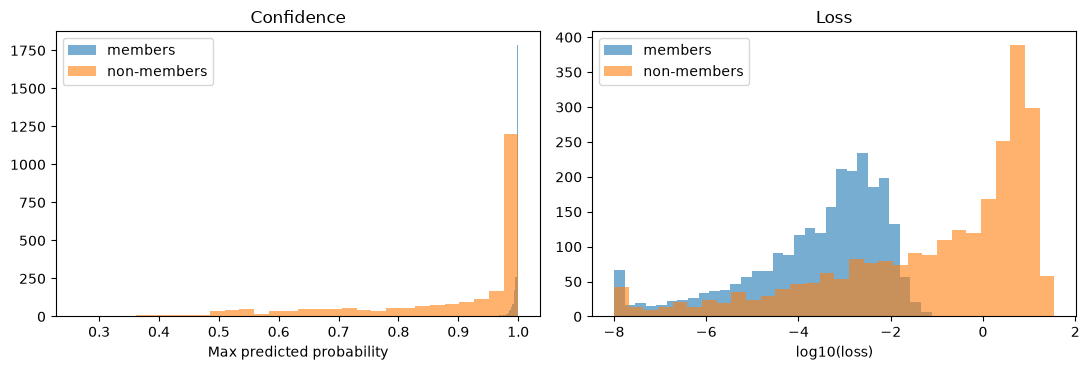

In [19]:
sig_mem = get_signals(target, X_mem, y_mem)
sig_non = get_signals(target, X_non, y_non)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

ax[0].hist(sig_mem['conf'], bins=30, alpha=.6, label='members')
ax[0].hist(sig_non['conf'], bins=30, alpha=.6, label='non-members')
ax[0].set_xlabel('Max predicted probability'); ax[0].set_title('Confidence'); ax[0].legend()

ax[1].hist(np.log10(sig_mem['loss'] + 1e-8), bins=30, alpha=.6, label='members')
ax[1].hist(np.log10(sig_non['loss'] + 1e-8), bins=30, alpha=.6, label='non-members')
ax[1].set_xlabel('log10(loss)'); ax[1].set_title('Loss'); ax[1].legend()

plt.tight_layout(); plt.show()

### 5.3 Attack results
**Reading the table:** AUC of 0.83 means an attacker with a simple threshold ranks a random member above a random non-member 83% of the time. The loss attack beats the confidence attack because it uses the true label. `Loss` and `Logit margin` are identical by construction (see the note in Section 3.5).

**An honest caveat.** TPR at 1% FPR is only about 0.017, barely above the 0.01 of random guessing. So on average the leak is strong, but a single global threshold cannot confidently *single out* individuals. The confidence histogram above shows the likely reason directly: a large share of non-members are also classified with near-certainty (easy images), so at a very strict false-alarm rate a single threshold has to sit above almost all of them and misses most members. The shadow-model attack in Section 6 combines several signals and triples the low-FPR rate.

In [20]:
sig_mem = get_signals(target, X_mem, y_mem)
sig_non = get_signals(target, X_non, y_non)

res_conf   = attack_metrics(sig_mem['conf'],   sig_non['conf'])
res_loss   = attack_metrics(-sig_mem['loss'],  -sig_non['loss'])
res_margin = attack_metrics(sig_mem['margin'], sig_non['margin'])

table = pd.DataFrame({n: {k: r[k] for k in ['auc', 'best_acc', 'tpr@1%fpr', 'tpr@0.1%fpr']}
                      for n, r in [('Confidence', res_conf), ('Loss', res_loss), ('Logit margin', res_margin)]}).T
display(table.round(3))

,auc,best_acc,tpr@1%fpr,tpr@0.1%fpr
Confidence,0.777,0.764,0.017,0.002
Loss,0.830,0.833,0.017,0.002
Logit margin,0.830,0.833,0.017,0.002


### 5.4 Entropy attack
A third score that uses the whole probability vector instead of one number. Low entropy means the model is concentrated on one class, which is member-like. Its performance is close to the confidence attack.

In [21]:
def entropy(p):
    return -(p * np.log(p + 1e-12)).sum(1)

res_ent = attack_metrics(-entropy(sig_mem['probs']), -entropy(sig_non['probs']))   # low entropy = member
print(f"Entropy attack: AUC={res_ent['auc']:.3f}  TPR@1%FPR={res_ent['tpr@1%fpr']:.3f}")

Entropy attack: AUC=0.776  TPR@1%FPR=0.016


---
# 6. Shadow-model attack (a realistic attacker)

**Problem.** In Section 5 we picked thresholds using ground truth, which a real attacker does not have.

**Idea (Shokri et al.).**
1. The attacker collects data from the same distribution (our *shadow* groups).
2. They train their own copy of the model, the **shadow model**, on the shadow members. Now they *know* which samples are members of *that* model.
3. They train an **attack classifier** that separates the shadow model's outputs on shadow members from its outputs on shadow non-members.
4. They apply that classifier to the **target** model's outputs, without ever seeing the target's training set.

The attacker learns what a member's output looks like instead of guessing one global threshold.

### 6.1 Train the shadow model
The shadow uses the **same recipe** as the target (same architecture, epochs, learning rate), which assumes the attacker guessed the training pipeline correctly. Only the data and the random seed differ. The sanity check confirms the shadow overfits just like the target (100% member accuracy, about 50 to 54% on unseen data), so it is a good imitation.

In [22]:
shadow_name = f'shadow_{tag}'
shadow = SmallCNN().to(device)

if load_model_if_exists(shadow, shadow_name):
    print('Loaded saved shadow model, skipping training')
else:
    print('Training shadow model...')
    set_seed(CONFIG['seed'] + 1)            # different seed, different data
    shadow = SmallCNN().to(device)
    shadow, _ = train_model(shadow, X_smem_gpu, y_smem_gpu, epochs=CONFIG['epochs'],
                            lr=CONFIG['lr'], bs=CONFIG['batch_size'], augment=CONFIG['augment'])
    save_model(shadow, shadow_name)

# Sanity check: the shadow should overfit like the target does
for nm, mdl, (Xm, ym), (Xn, yn) in [('target', target, (X_mem, y_mem), (X_non, y_non)),
                                    ('shadow', shadow, (X_smem, y_smem), (X_snon, y_snon))]:
    print(f'{nm}: member acc={accuracy(mdl, Xm, ym):.3f} | non-member acc={accuracy(mdl, Xn, yn):.3f} | test acc={accuracy(mdl, X_test, y_test):.3f}')

Loaded saved shadow model, skipping training
target: member acc=1.000 | non-member acc=0.521 | test acc=0.535
shadow: member acc=1.000 | non-member acc=0.537 | test acc=0.523


### 6.2 Turn model outputs into attack features
For each image, the attack classifier sees seven numbers: the three largest probabilities, the loss, the logit margin, the output entropy, and whether the prediction was correct. Shadow members are labelled 1 and shadow non-members 0.

In [23]:
def attack_features(sig):
    p = sig['probs']
    top3 = -np.sort(-p, axis=1)[:, :3]                       # three largest probabilities
    ent  = -(p * np.log(p + 1e-12)).sum(1)                   # entropy of the output
    return np.column_stack([top3, sig['loss'], sig['margin'], ent, sig['correct'].astype(float)])

s_mem = get_signals(shadow, X_smem, y_smem)
s_non = get_signals(shadow, X_snon, y_snon)

X_att = np.vstack([attack_features(s_mem), attack_features(s_non)])
y_att = np.concatenate([np.ones(len(s_mem['loss'])), np.zeros(len(s_non['loss']))])
print('Attack training set:', X_att.shape, '| members:', int(y_att.sum()))

Attack training set: (5000, 7) | members: 2500


### 6.3 Train the attack classifier (with a held-out check)
A gradient-boosting classifier learns to separate members from non-members. The **held-out check** matters: if the classifier merely memorized the shadow samples, its AUC on held-out shadow data would be near 0.5. A value around 0.86 means it learned a general rule. The final classifier is then refit on all shadow data.

In [24]:
from sklearn.model_selection import train_test_split

Xa_tr, Xa_va, ya_tr, ya_va = train_test_split(X_att, y_att, test_size=0.3, stratify=y_att, random_state=0)

attack_clf = GradientBoostingClassifier(n_estimators=150, max_depth=3, random_state=0).fit(Xa_tr, ya_tr)

val_auc = roc_auc_score(ya_va, attack_clf.predict_proba(Xa_va)[:, 1])
print(f'Attack classifier AUC on held-out SHADOW data: {val_auc:.3f}')

# Refit on all shadow data for the final attack
attack_clf = GradientBoostingClassifier(n_estimators=150, max_depth=3, random_state=0).fit(X_att, y_att)

Attack classifier AUC on held-out SHADOW data: 0.862


### 6.4 Attack the real target
The classifier is applied to the **target** model's outputs. The attacker never touched the target's training data.

**Result:** AUC rises from 0.830 (loss threshold) to **0.861**, and TPR @ 1% FPR rises from 0.017 to **0.051**, about three times higher. A realistic attacker who has no knowledge of the target's data does at least as well as the idealized threshold attacker, and does much better at the strict low-false-alarm end.

In [25]:
sig_mem = get_signals(target, X_mem, y_mem)
sig_non = get_signals(target, X_non, y_non)

p_mem = attack_clf.predict_proba(attack_features(sig_mem))[:, 1]
p_non = attack_clf.predict_proba(attack_features(sig_non))[:, 1]
res_shadow = attack_metrics(p_mem, p_non)

# Earlier attacks, recomputed from the stable signals
res_conf   = attack_metrics(sig_mem['conf'],   sig_non['conf'])
res_loss   = attack_metrics(-sig_mem['loss'],  -sig_non['loss'])
res_margin = attack_metrics(sig_mem['margin'], sig_non['margin'])

allres = [('Confidence', res_conf), ('Loss', res_loss), ('Logit margin', res_margin), ('Shadow model', res_shadow)]
table = pd.DataFrame({n: {k: r[k] for k in ['auc', 'best_acc', 'tpr@1%fpr', 'tpr@0.1%fpr']} for n, r in allres}).T
display(table.round(3))

,auc,best_acc,tpr@1%fpr,tpr@0.1%fpr
Confidence,0.777,0.764,0.017,0.002
Loss,0.830,0.833,0.017,0.002
Logit margin,0.830,0.833,0.017,0.002
Shadow model,0.861,0.832,0.051,0.008


### 6.5 ROC curves for all attacks
Left: standard ROC. Right: log-log axes, which magnify the low-FPR corner where dangerous attacks live. The dashed line is random guessing. The shadow-model curve sits clearly above the threshold attacks at low FPR. (The loss and margin curves lie on top of each other, as explained earlier.)

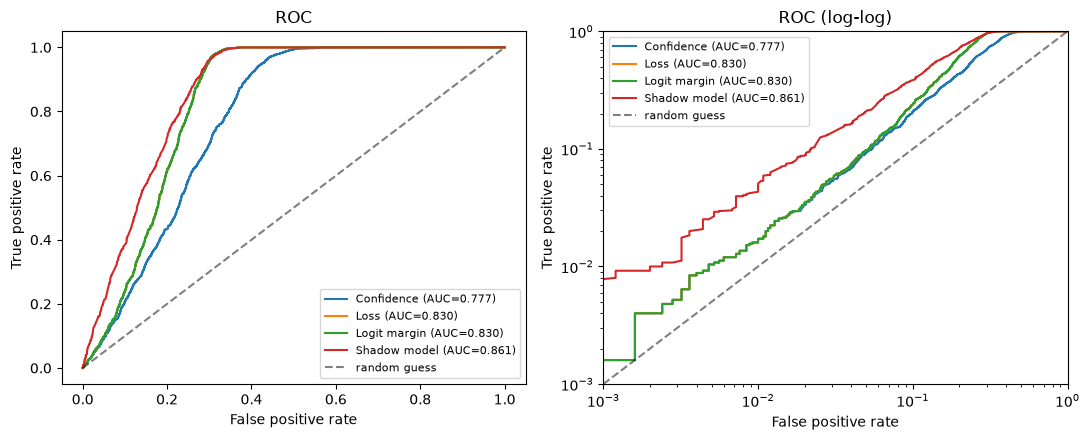

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, log in zip(ax, [False, True]):
    for n, r in allres:
        a.plot(r['fpr'], r['tpr'], label=f"{n} (AUC={r['auc']:.3f})")
    lo = 1e-3 if log else 0
    a.plot([lo, 1], [lo, 1], 'k--', alpha=.5, label='random guess')
    if log:
        a.set_xscale('log'); a.set_yscale('log'); a.set_xlim(1e-3, 1); a.set_ylim(1e-3, 1)
    a.set_xlabel('False positive rate'); a.set_ylabel('True positive rate')
    a.set_title('ROC (log-log)' if log else 'ROC'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

save_obj({n: {k: v for k, v in r.items() if k not in ('fpr', 'tpr')} for n, r in allres}, f'attacks_{tag}')

---
# 7. Why does it work? Leakage vs. overfitting

**Hypothesis:** the attack works because the model overfits. If true, then (a) leakage should grow as training continues, (b) it should be reproducible across random seeds, and (c) it should be stronger when the training set is smaller. We test all three.

### 7.1 A reusable evaluation function
`summarize` bundles everything we measure for one model: train/test accuracy, the generalization gap, the loss-based and margin-based AUCs, TPR at 1% FPR, a **label-only attack** (the attacker sees just the predicted class and guesses "member" when it is correct), and `worst_case_auc`, the strongest attack available. It is reused for every defense in Section 8.

In [27]:
def summarize(name, model, label_only=False):
    s_m = get_signals(model, X_mem, y_mem)
    s_n = get_signals(model, X_non, y_non)
    tr_acc = float(s_m['correct'].mean())
    te_acc = float(accuracy(model, X_test, y_test))

    # label-only attack: attacker sees only the predicted label, guesses "member" if it is correct
    lab = attack_metrics(s_m['correct'].astype(float), s_n['correct'].astype(float))

    if label_only:
        loss_auc = margin_auc = tpr1 = np.nan
    else:
        r_loss = attack_metrics(-s_m['loss'], -s_n['loss'])
        r_marg = attack_metrics(s_m['margin'], s_n['margin'])
        loss_auc, margin_auc, tpr1 = r_loss['auc'], r_marg['auc'], r_marg['tpr@1%fpr']

    return {'setting': name, 'train_acc': tr_acc, 'test_acc': te_acc, 'gap': tr_acc - te_acc,
            'loss_auc': loss_auc, 'margin_auc': margin_auc, 'tpr@1%fpr': tpr1,
            'label_auc': lab['auc'],
            'worst_case_auc': float(np.nanmax([loss_auc, margin_auc, lab['auc']]))}

### 7.2 Single training run, paused at eight epochs
We train one fresh model and measure it at epochs 1, 2, 3, 5, 8, 12, 20 and 30. Expected: at epoch 1 the gap is about 0 and the AUC about 0.52 (nothing memorized, nothing leaked); by epoch 30 the gap is about 0.46 and the AUC about 0.84.

In [28]:
study_name = f'epoch_study_{tag}'
epoch_df = load_obj(study_name)

if epoch_df is not None:
    print('Loaded saved epoch study')
else:
    print('Running epoch study...')
    rows = []
    set_seed(CONFIG['seed'])                       # same seed as the target model
    m = SmallCNN().to(device)
    snaps = (1, 2, 3, 5, 8, 12, 20, 30)

    def on_snapshot(epoch, model):
        r = summarize(f'epoch {epoch}', model)
        r['epoch'] = epoch
        rows.append(r)

    train_model(m, X_mem_gpu, y_mem_gpu, epochs=max(snaps), lr=CONFIG['lr'],
                bs=CONFIG['batch_size'], augment=CONFIG['augment'],
                snapshots=snaps, callback=on_snapshot)
    epoch_df = pd.DataFrame(rows)
    save_obj(epoch_df, study_name)

display(epoch_df[['epoch', 'train_acc', 'test_acc', 'gap', 'loss_auc', 'margin_auc', 'tpr@1%fpr']].round(3))

Loaded saved epoch study


,epoch,train_acc,test_acc,gap,loss_auc,margin_auc,tpr@1%fpr
0,1,0.278,0.286,-0.008,0.516,0.516,0.015
1,2,0.380,0.367,0.013,0.532,0.532,0.009
2,3,0.454,0.418,0.035,0.538,0.538,0.015
3,5,0.532,0.460,0.072,0.563,0.563,0.010
4,8,0.604,0.480,0.124,0.601,0.601,0.011
5,12,0.810,0.520,0.290,0.688,0.688,0.018
6,20,0.972,0.523,0.449,0.789,0.789,0.022
7,30,1.000,0.537,0.463,0.835,0.835,0.015


### 7.3 Plots: overfitting, leakage, and gap vs. leakage
- **(a)** the generalization gap opens up as training continues.
- **(b)** the attack AUC rises with it.
- **(c)** the key figure: attack AUC plotted against the gap. The relationship is almost a straight line (Pearson 0.995, Spearman 1.0).

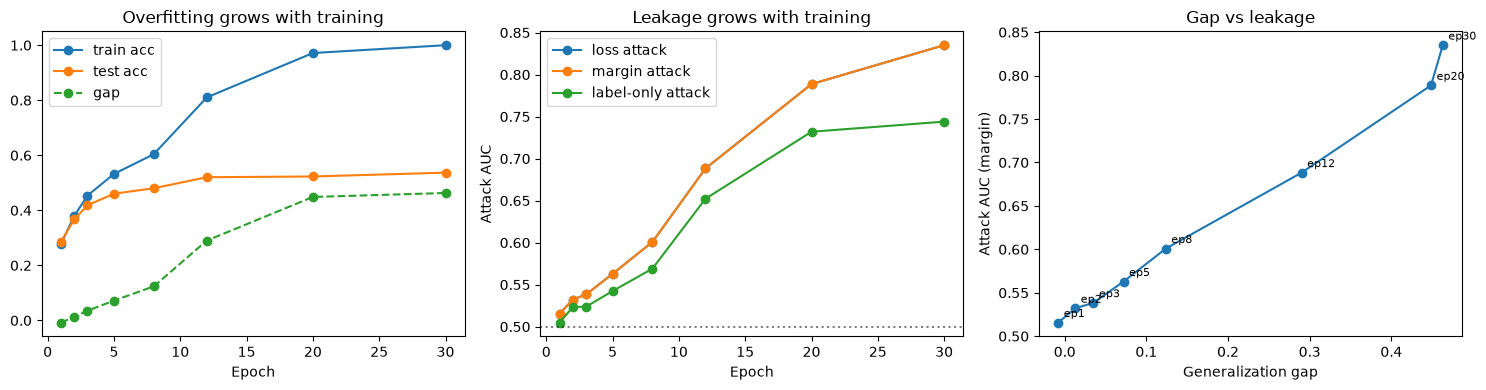

Correlation between gap and attack AUC: Pearson=0.995, Spearman=1.000


In [29]:
from scipy.stats import pearsonr, spearmanr

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# (a) accuracy and gap over training
ax[0].plot(epoch_df['epoch'], epoch_df['train_acc'], 'o-', label='train acc')
ax[0].plot(epoch_df['epoch'], epoch_df['test_acc'],  'o-', label='test acc')
ax[0].plot(epoch_df['epoch'], epoch_df['gap'],       'o--', label='gap')
ax[0].set_xlabel('Epoch'); ax[0].set_title('Overfitting grows with training'); ax[0].legend()

# (b) attack strength over training
ax[1].plot(epoch_df['epoch'], epoch_df['loss_auc'],   'o-', label='loss attack')
ax[1].plot(epoch_df['epoch'], epoch_df['margin_auc'], 'o-', label='margin attack')
ax[1].plot(epoch_df['epoch'], epoch_df['label_auc'],  'o-', label='label-only attack')
ax[1].axhline(0.5, color='k', ls=':', alpha=.5)
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Attack AUC'); ax[1].set_title('Leakage grows with training'); ax[1].legend()

# (c) the key figure: gap vs leakage
ax[2].plot(epoch_df['gap'], epoch_df['margin_auc'], 'o-')
for _, r in epoch_df.iterrows():
    ax[2].annotate(f"ep{int(r['epoch'])}", (r['gap'], r['margin_auc']), textcoords='offset points', xytext=(4, 4), fontsize=8)
ax[2].set_xlabel('Generalization gap'); ax[2].set_ylabel('Attack AUC (margin)'); ax[2].set_title('Gap vs leakage')

plt.tight_layout(); plt.show()

pr = pearsonr(epoch_df['gap'], epoch_df['margin_auc'])[0]
sr = spearmanr(epoch_df['gap'], epoch_df['margin_auc'])[0]
print(f'Correlation between gap and attack AUC: Pearson={pr:.3f}, Spearman={sr:.3f}')

### 7.4 Repeat with three random seeds
A single run could be luck. Repeating with seeds 0, 1 and 2 and averaging gives mean ± std. We also record the average loss of members and non-members at every epoch.

**Third panel in the next plot:** member loss falls toward zero while non-member loss climbs. That widening distance *is* the attack signal.

> **Caveat.** The 24 pooled points (3 seeds x 8 epochs) come from only three training trajectories, so they are not 24 independent samples. Treat r = 0.996 as "strong association", not as a formal significance test. The data split is fixed, so this measures training randomness only.

In [30]:
seeds = [0, 1, 2]
snaps = (1, 2, 3, 5, 8, 12, 20, 30)
ms_name = f'multiseed_{tag}'
ms_df = load_obj(ms_name)

if ms_df is not None:
    print('Loaded saved multi-seed study')
else:
    print('Running multi-seed study...')
    rows = []
    for sd in seeds:
        set_seed(sd)
        m = SmallCNN().to(device)

        def on_snapshot(epoch, model, sd=sd):
            r = summarize(f'epoch {epoch}', model)
            r['epoch'], r['seed'] = epoch, sd
            sm = get_signals(model, X_mem, y_mem)
            sn = get_signals(model, X_non, y_non)
            r['mem_loss'], r['non_loss'] = sm['loss'].mean(), sn['loss'].mean()
            rows.append(r)

        train_model(m, X_mem_gpu, y_mem_gpu, epochs=max(snaps), lr=CONFIG['lr'],
                    bs=CONFIG['batch_size'], augment=CONFIG['augment'],
                    snapshots=snaps, callback=on_snapshot)
        print(f'  seed {sd} done')
    ms_df = pd.DataFrame(rows)
    save_obj(ms_df, ms_name)

agg = ms_df.groupby('epoch')[['train_acc', 'test_acc', 'gap', 'loss_auc', 'margin_auc',
                              'label_auc', 'mem_loss', 'non_loss']].agg(['mean', 'std'])
display(agg[['gap', 'margin_auc', 'loss_auc']].round(3))

Loaded saved multi-seed study


gap        margin_auc        loss_auc       
        mean    std       mean    std     mean    std
epoch                                                
1      0.001  0.010      0.522  0.006    0.522  0.006
2      0.014  0.003      0.531  0.003    0.531  0.003
3      0.028  0.007      0.535  0.003    0.535  0.003
5      0.069  0.002      0.561  0.002    0.561  0.002
8      0.135  0.012      0.602  0.006    0.602  0.006
12     0.267  0.033      0.677  0.017    0.677  0.017
20     0.462  0.019      0.795  0.019    0.795  0.019
30     0.468  0.009      0.836  0.014    0.836  0.014

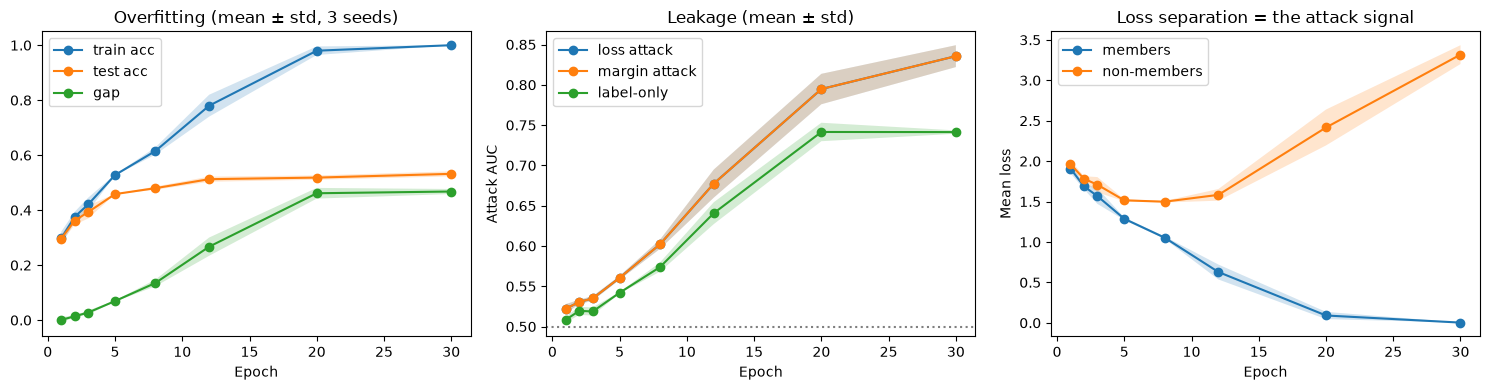

Gap vs margin-attack AUC, all seeds pooled: Pearson r = 0.996


In [31]:
def band(ax, col, label):
    mu, sd = agg[(col, 'mean')], agg[(col, 'std')].fillna(0)
    ax.plot(agg.index, mu, 'o-', label=label)
    ax.fill_between(agg.index, mu - sd, mu + sd, alpha=.2)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

band(ax[0], 'train_acc', 'train acc'); band(ax[0], 'test_acc', 'test acc'); band(ax[0], 'gap', 'gap')
ax[0].set_xlabel('Epoch'); ax[0].set_title('Overfitting (mean ± std, 3 seeds)'); ax[0].legend()

band(ax[1], 'loss_auc', 'loss attack'); band(ax[1], 'margin_auc', 'margin attack'); band(ax[1], 'label_auc', 'label-only')
ax[1].axhline(0.5, color='k', ls=':', alpha=.5)
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Attack AUC'); ax[1].set_title('Leakage (mean ± std)'); ax[1].legend()

band(ax[2], 'mem_loss', 'members'); band(ax[2], 'non_loss', 'non-members')
ax[2].set_xlabel('Epoch'); ax[2].set_ylabel('Mean loss'); ax[2].set_title('Loss separation = the attack signal'); ax[2].legend()

plt.tight_layout(); plt.show()

# correlation over all seeds and epochs (24 points instead of 8)
from scipy.stats import pearsonr
print('Gap vs margin-attack AUC, all seeds pooled: Pearson r = %.3f' % pearsonr(ms_df['gap'], ms_df['margin_auc'])[0])

### 7.5 Dataset-size study: less data means more leakage
A second, independent test of the same cause. Smaller training sets are memorized more easily, so they should leak more. We train on 500, 1,000, 2,500 and 5,000 images (2 seeds each); non-members come from a separate region of the pool.

**Result:** gap falls from 0.61 to 0.41 and attack AUC from 0.90 to 0.78 as data grows, with no reversals. More data improved *both* utility (test accuracy 0.39 to 0.59) and privacy, but even at 5,000 images leakage is far from zero.

 **Caveats.** Only two seeds per size (a std of 0.000 just means the two runs agreed to three decimals). TPR @ 1% FPR is noisy at small sizes because 1% of 500 non-members is only 5 samples; rely on AUC.

Loaded saved size study


test_acc           gap        margin_auc        tpr@1%fpr       
            mean    std   mean    std       mean    std      mean    std
n_train                                                                 
500        0.391  0.006  0.609  0.006      0.900  0.011     0.032  0.006
1000       0.454  0.008  0.546  0.008      0.882  0.010     0.030  0.006
2500       0.527  0.009  0.473  0.009      0.826  0.000     0.013  0.004
5000       0.590  0.003  0.410  0.003      0.780  0.000     0.012  0.001

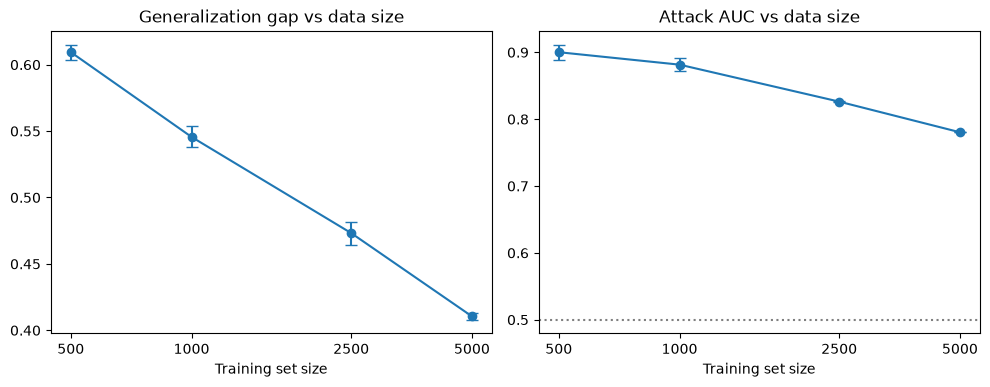

In [32]:
sizes = [500, 1000, 2500, 5000]
size_name = f'size_study_{tag}'
size_df = load_obj(size_name)

if size_df is not None:
    print('Loaded saved size study')
else:
    print('Running dataset-size study...')
    rows = []
    for n in sizes:
        Xm, ym = X_all[idx[:n]], y_all[idx[:n]]                    # members
        Xn, yn = X_all[idx[20000:20000 + n]], y_all[idx[20000:20000 + n]]   # non-members, disjoint
        for sd in [0, 1]:
            set_seed(sd)
            m = SmallCNN().to(device)
            train_model(m, Xm.to(device), ym.to(device), epochs=CONFIG['epochs'], lr=CONFIG['lr'],
                        bs=CONFIG['batch_size'], augment=CONFIG['augment'])
            sm, sn = get_signals(m, Xm, ym), get_signals(m, Xn, yn)
            te = accuracy(m, X_test, y_test)
            r = attack_metrics(sm['margin'], sn['margin'])
            rows.append({'n_train': n, 'seed': sd, 'train_acc': sm['correct'].mean(), 'test_acc': te,
                         'gap': sm['correct'].mean() - te, 'margin_auc': r['auc'], 'tpr@1%fpr': r['tpr@1%fpr']})
        print(f'  n={n} done')
    size_df = pd.DataFrame(rows)
    save_obj(size_df, size_name)

sz = size_df.groupby('n_train')[['train_acc', 'test_acc', 'gap', 'margin_auc', 'tpr@1%fpr']].agg(['mean', 'std'])
display(sz[['test_acc', 'gap', 'margin_auc', 'tpr@1%fpr']].round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, col, title in [(ax[0], 'gap', 'Generalization gap'), (ax[1], 'margin_auc', 'Attack AUC')]:
    mu, sd = sz[(col, 'mean')], sz[(col, 'std')].fillna(0)
    a.errorbar(sz.index, mu, yerr=sd, fmt='o-', capsize=4)
    a.set_xscale('log'); a.set_xlabel('Training set size'); a.set_title(title + ' vs data size')
ax[1].axhline(0.5, color='k', ls=':', alpha=.5)
plt.tight_layout();
for a in ax:
    a.set_xticks(sizes)
    a.set_xticklabels([str(s) for s in sizes])
    a.minorticks_off()
plt.show()

---
# 8. Defenses and the privacy-utility trade-off

We now try to fix the leak. Every defense is trained, then scored on two axes:
- **Utility** = test accuracy (higher is better)
- **Privacy risk** = strongest attack AUC (lower is better; 0.5 means the attacker is only guessing)

| Defense | Idea |
|---|---|
| Early stopping (5 epochs) | stop before the model memorizes |
| Dropout + weight decay | regularization reduces exact fitting |
| Label smoothing | trains against soft targets so the model is never extremely confident |
| Data augmentation | the model never sees exactly the same pixels twice |
| Augmentation + dropout + weight decay | all regularizers combined |
| Label-only API | hide the probabilities; return only the predicted class |
| **DP-SGD** (differential privacy) | clip each sample's gradient and add noise; gives a *mathematical* privacy guarantee measured by epsilon (smaller = more private) |

### 8.1 The five standard defenses
`run_defense` trains (or loads) one defended model, evaluates it, and caches the result. `fit(...)` builds a training recipe from the settings. The baseline and the label-only API reuse the target model you already trained. Each defense here is a **single seed**; Section 8.4 repeats the main ones over three seeds.

In [33]:
rows_cache = load_obj(f'defense_rows_{tag}', default={})

def run_defense(key, label, train_fn, dropout=0.0):
    # trains (or loads) one defended model, evaluates it, and caches the result row
    if key in rows_cache:
        return
    mname = f'def_{key}_{tag}'
    m = SmallCNN(dropout).to(device)
    if not load_model_if_exists(m, mname):
        print(f'Training: {label}')
        m = train_fn()
        save_model(m, mname)
    rows_cache[key] = summarize(label, m)
    save_obj(rows_cache, f'defense_rows_{tag}')

def fit(**kw):
    # returns a function that trains a fresh model with the given settings
    def _go():
        set_seed(CONFIG['seed'])
        m = SmallCNN(kw.get('dropout', 0.0)).to(device)
        epochs = kw.get('epochs', CONFIG['epochs'])
        m, _ = train_model(m, X_mem_gpu, y_mem_gpu, epochs=epochs, lr=CONFIG['lr'],
                           bs=CONFIG['batch_size'], wd=kw.get('wd', 0.0),
                           ls=kw.get('ls', 0.0), augment=kw.get('augment', False))
        return m
    return _go

run_defense('early',     'Early stop (5 ep)',    fit(epochs=5))
run_defense('wd_drop',   'Dropout + weight decay', fit(dropout=0.5, wd=1e-3), dropout=0.5)
run_defense('smooth',    'Label smoothing',      fit(ls=0.2))
run_defense('augment',   'Augmentation',         fit(augment=True))
run_defense('combo',     'Aug + dropout + wd',   fit(augment=True, dropout=0.5, wd=1e-3), dropout=0.5)

# baseline and label-only API reuse the target model you already trained
rows_cache['baseline']   = summarize('Baseline (30 ep)', target)
rows_cache['label_only'] = summarize('Label-only API', target, label_only=True)
save_obj(rows_cache, f'defense_rows_{tag}')
print('Standard defenses done')

Standard defenses done


### 8.2 Differential privacy (DP-SGD) with Opacus
Opacus wraps the model, optimizer and data loader so that training clips every sample's gradient and adds Gaussian noise. We train at three privacy levels (epsilon = 2, 8, 30, with delta = 1e-5). Smaller epsilon means stronger privacy and more noise.

**Caveat.** The DP settings are *untuned* (batch size 128, 20 epochs, Adam at 1e-3, clip 1.0). Accuracy of 0.25 to 0.33 is low; with 2,500 training images DP-SGD is genuinely hard, but better tuning would likely recover some accuracy. An optional tuned run is provided in Section 8.6.

In [34]:
from opacus import PrivacyEngine

def train_dp(eps, epochs=20, bs=128, delta=1e-5, clip=1.0, seed=0):
    set_seed(seed)
    m = SmallCNN().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(X_mem, y_mem), batch_size=bs)   # Opacus needs a DataLoader
    pe = PrivacyEngine()
    m, opt, loader = pe.make_private_with_epsilon(
        module=m, optimizer=opt, data_loader=loader, epochs=epochs,
        target_epsilon=eps, target_delta=delta, max_grad_norm=clip)
    crit = nn.CrossEntropyLoss()
    for ep in range(epochs):
        m.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            crit(m(xb), yb).backward()
            opt.step()
    return m._module          # the plain trained network, without Opacus wrapping

for eps in [2.0, 8.0, 30.0]:
    run_defense(f'dp{eps:g}', f'DP-SGD (eps={eps:g})', lambda e=eps: train_dp(e))
    rows_cache[f'dp{eps:g}']['epsilon'] = eps
save_obj(rows_cache, f'defense_rows_{tag}')
print('DP-SGD done')

DP-SGD done


### 8.3 Results table (single seed)
Columns: `gap` = generalization gap; `loss_auc` / `margin_auc` = threshold attacks; `label_auc` = label-only attack; `worst_case_auc` = the strongest attack for that setting. The label-only API row has no loss/margin value because the attacker cannot see probabilities there.

**What stands out**
- **Label smoothing made leakage worse** (0.913 vs 0.830 baseline).
- **Hiding probabilities barely helps:** the label-only attack still reaches AUC 0.739, because the leak comes from the generalization gap, not from the output format.
- **Augmentation helps utility and privacy at once** (test accuracy 0.580, AUC 0.644).
- **DP-SGD pushes the attack to about 0.52**, close to random, but at a large accuracy cost.

In [35]:
order = ['baseline', 'early', 'wd_drop', 'smooth', 'augment', 'combo', 'label_only', 'dp30', 'dp8', 'dp2']
res_df = pd.DataFrame([rows_cache[k] for k in order if k in rows_cache])
display(res_df[['setting', 'train_acc', 'test_acc', 'gap', 'loss_auc', 'margin_auc',
                'tpr@1%fpr', 'label_auc', 'worst_case_auc']].round(3))

,setting,train_acc,test_acc,gap,loss_auc,margin_auc,tpr@1%fpr,label_auc,worst_case_auc
0,Baseline (30 ep),1.000,0.535,0.465,0.830,0.830,0.017,0.739,0.830
1,Early stop (5 ep),0.531,0.456,0.075,0.563,0.563,0.008,0.544,0.563
2,Dropout + weight decay,0.963,0.541,0.422,0.770,0.770,0.012,0.718,0.770
3,Label smoothing,1.000,0.532,0.468,0.913,0.913,0.000,0.743,0.913
4,Augmentation,0.800,0.580,0.220,0.644,0.644,0.012,0.614,0.644
5,Aug + dropout + wd,0.644,0.553,0.090,0.567,0.567,0.011,0.547,0.567
6,Label-only API,1.000,0.535,0.465,NaN,NaN,NaN,0.739,0.739
7,DP-SGD (eps=30),0.320,0.326,-0.006,0.526,0.526,0.006,0.515,0.526
8,DP-SGD (eps=8),0.287,0.286,0.001,0.521,0.521,0.005,0.511,0.521
9,DP-SGD (eps=2),0.253,0.251,0.002,0.517,0.517,0.010,0.510,0.517


**Trade-off plot.** Left: each defense as one point; the ideal corner is the **bottom right** (high accuracy, low attack AUC). Right: attack AUC per defense for each attack type; the dashed line is random guessing (perfect privacy).

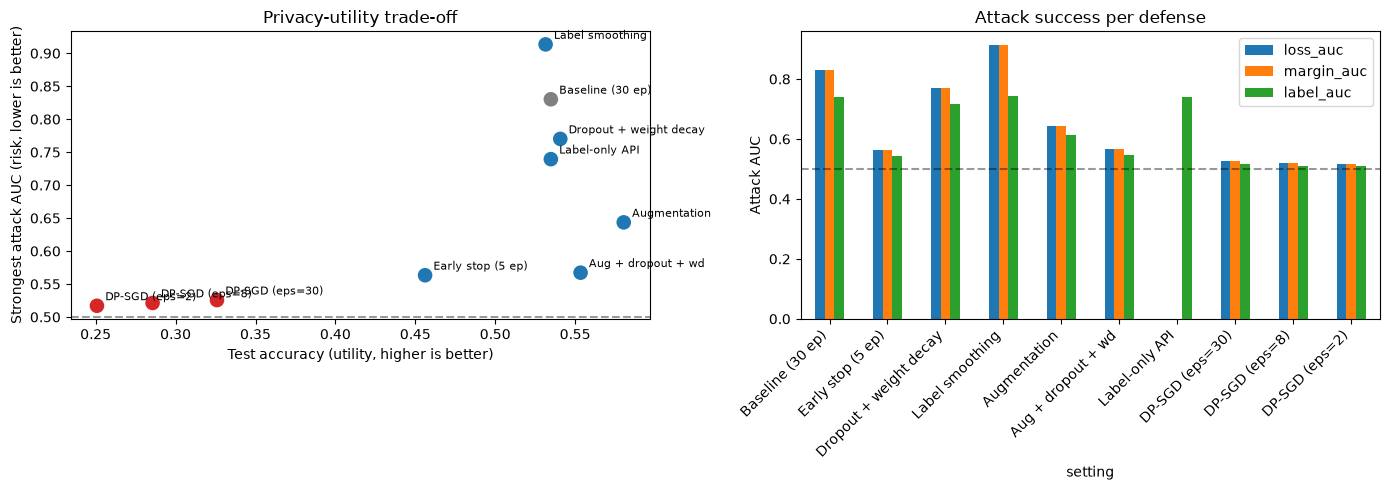

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# (a) the trade-off: the ideal corner is the bottom right (high accuracy, low attack AUC)
colors = ['gray' if 'Baseline' in s else 'tab:red' if 'DP' in s else 'tab:blue' for s in res_df['setting']]
ax[0].scatter(res_df['test_acc'], res_df['worst_case_auc'], s=90, c=colors)
for _, r in res_df.iterrows():
    ax[0].annotate(r['setting'], (r['test_acc'], r['worst_case_auc']), textcoords='offset points', xytext=(6, 4), fontsize=8)
ax[0].axhline(0.5, color='k', ls='--', alpha=.4)
ax[0].set_xlabel('Test accuracy (utility, higher is better)')
ax[0].set_ylabel('Strongest attack AUC (risk, lower is better)')
ax[0].set_title('Privacy-utility trade-off')

# (b) attack AUC by defense and attack type
plot_df = res_df.set_index('setting')[['loss_auc', 'margin_auc', 'label_auc']]
plot_df.plot(kind='bar', ax=ax[1])
ax[1].axhline(0.5, color='k', ls='--', alpha=.4)
ax[1].set_ylabel('Attack AUC'); ax[1].set_title('Attack success per defense')
ax[1].tick_params(axis='x', rotation=45)
plt.setp(ax[1].get_xticklabels(), ha='right')

plt.tight_layout(); plt.show()

### 8.4 Main defenses repeated over three seeds
Single runs can mislead. Here the six non-DP settings are trained with seeds 0, 1, 2; every run is cached the moment it finishes, so an interrupted run resumes where it stopped. This measures **training randomness only** (the data split stays fixed).

In [37]:
seeds = [0, 1, 2]
ms_def_name = f'defense_multiseed_{tag}'
ms_def = load_obj(ms_def_name, default=[])
done = {(r['key'], r['seed']) for r in ms_def}

configs = {
    'baseline': ('Baseline (30 ep)',        dict()),
    'early':    ('Early stop (5 ep)',       dict(epochs=5)),
    'wd_drop':  ('Dropout + weight decay',  dict(dropout=0.5, wd=1e-3)),
    'smooth':   ('Label smoothing',         dict(ls=0.2)),
    'augment':  ('Augmentation',            dict(augment=True)),
    'combo':    ('Aug + dropout + wd',      dict(augment=True, dropout=0.5, wd=1e-3)),
}

for key, (label, kw) in configs.items():
    for sd in seeds:
        if (key, sd) in done:
            continue
        set_seed(sd)
        m = SmallCNN(kw.get('dropout', 0.0)).to(device)
        m, _ = train_model(m, X_mem_gpu, y_mem_gpu,
                           epochs=kw.get('epochs', CONFIG['epochs']), lr=CONFIG['lr'],
                           bs=CONFIG['batch_size'], wd=kw.get('wd', 0.0),
                           ls=kw.get('ls', 0.0), augment=kw.get('augment', False))
        r = summarize(label, m)
        r.update(key=key, seed=sd)
        ms_def.append(r)
        save_obj(ms_def, ms_def_name)          # save after every run
        print(f'{label:24s} seed {sd}: test_acc={r["test_acc"]:.3f}  worst_case_auc={r["worst_case_auc"]:.3f}')

print('All runs complete:', len(ms_def))

All runs complete: 18


**Mean ± std over three seeds** (compact table for the report):

In [38]:
msd = pd.DataFrame(ms_def)
cols = ['test_acc', 'gap', 'loss_auc', 'label_auc', 'worst_case_auc', 'tpr@1%fpr']
agg_def = msd.groupby('setting', sort=False)[cols].agg(['mean', 'std'])

# compact "mean ± std" view for your report
pretty = pd.DataFrame({c: [f"{agg_def.loc[s, (c,'mean')]:.3f} ± {agg_def.loc[s, (c,'std')]:.3f}"
                           for s in agg_def.index] for c in cols}, index=agg_def.index)
display(pretty)

,test_acc,gap,loss_auc,label_auc,worst_case_auc,tpr@1%fpr
setting,,,,,,
Baseline (30 ep),0.529 ± 0.010,0.471 ± 0.010,0.833 ± 0.014,0.744 ± 0.005,0.833 ± 0.014,0.020 ± 0.003
Early stop (5 ep),0.460 ± 0.002,0.064 ± 0.006,0.561 ± 0.002,0.539 ± 0.003,0.561 ± 0.002,0.014 ± 0.004
Dropout + weight decay,0.540 ± 0.016,0.432 ± 0.012,0.784 ± 0.012,0.724 ± 0.003,0.784 ± 0.012,0.017 ± 0.004
Label smoothing,0.532 ± 0.015,0.468 ± 0.015,0.914 ± 0.005,0.743 ± 0.006,0.914 ± 0.005,0.000 ± 0.000
Augmentation,0.576 ± 0.005,0.203 ± 0.015,0.636 ± 0.015,0.608 ± 0.014,0.636 ± 0.015,0.013 ± 0.002
Aug + dropout + wd,0.565 ± 0.014,0.105 ± 0.007,0.572 ± 0.009,0.553 ± 0.007,0.572 ± 0.009,0.014 ± 0.003


**Trade-off with error bars.** The best region is the bottom right.

| Reading | Conclusion |
|---|---|
| Baseline, label smoothing and dropout + weight decay | strictly worse than augmentation and the combined defense (lower accuracy *and* higher AUC) |
| **Augmentation + dropout + weight decay** | best trade-off: AUC 0.572 ± 0.009 at 0.565 ± 0.014 accuracy |
| Early stopping | similar privacy (0.561 ± 0.002, overlapping bars) but about 10 points less accuracy than the combined defense, and about 7 points below the baseline |
| x-axis range is narrow (0.46 to 0.58) | privacy varies a lot across defenses while accuracy varies little, except for early stopping |

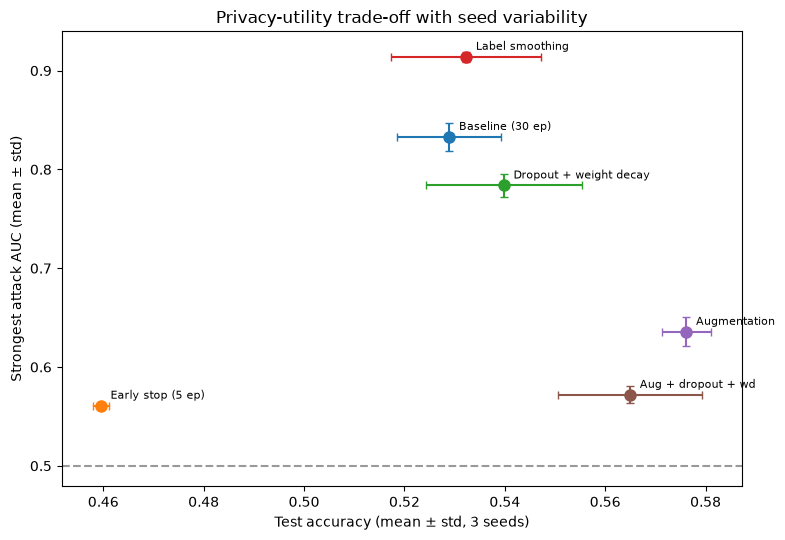

In [39]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for s in agg_def.index:
    x, xe = agg_def.loc[s, ('test_acc', 'mean')], agg_def.loc[s, ('test_acc', 'std')]
    y, ye = agg_def.loc[s, ('worst_case_auc', 'mean')], agg_def.loc[s, ('worst_case_auc', 'std')]
    ax.errorbar(x, y, xerr=xe, yerr=ye, fmt='o', capsize=3, ms=8)
    ax.annotate(s, (x, y), textcoords='offset points', xytext=(7, 5), fontsize=8)
ax.axhline(0.5, color='k', ls='--', alpha=.4)
ax.set_xlabel('Test accuracy (mean ± std, 3 seeds)')
ax.set_ylabel('Strongest attack AUC (mean ± std)')
ax.set_title('Privacy-utility trade-off with seed variability')
plt.tight_layout(); plt.show()

### 8.5 Is the label-smoothing result real?
Label smoothing raised leakage in the single run. Three seeds settle whether that was a fluke. **It was not:** label smoothing is higher than the baseline on all three seeds (0.916, 0.918, 0.909 vs. 0.833 ± 0.014). Its TPR @ 1% FPR is exactly 0.000 on every seed, which suggests members sit at a *moderate* loss (the smoothed target) rather than the extreme low-loss end, so a "lowest loss = member" rule fails in that corner. This is a hypothesis; the optional check in Section 8.6 tests it.

In [40]:
b = msd[msd.key == 'baseline']['worst_case_auc']
s = msd[msd.key == 'smooth']['worst_case_auc']
print(f'Baseline         worst-case AUC: {b.mean():.3f} ± {b.std():.3f}')
print(f'Label smoothing  worst-case AUC: {s.mean():.3f} ± {s.std():.3f}')
print('Per-seed smoothing AUCs:', s.round(3).tolist())
print('Smoothing higher than baseline on every seed:',
      all(msd[(msd.key=='smooth') & (msd.seed==sd)]['worst_case_auc'].values[0] >
          msd[(msd.key=='baseline') & (msd.seed==sd)]['worst_case_auc'].values[0] for sd in seeds))

Baseline         worst-case AUC: 0.833 ± 0.014
Label smoothing  worst-case AUC: 0.914 ± 0.005
Per-seed smoothing AUCs: [0.916, 0.918, 0.909]
Smoothing higher than baseline on every seed: True


---
# 9. Novel part: disparate vulnerability

**Question.** So far we reported one overall attack AUC. That can hide the fact that **some groups are much easier to attack than others**. Is privacy risk equal for everyone? We test:

1. **Per class:** are some CIFAR-10 classes more exposed than others, and is the difference larger than chance?
2. **Hard samples:** are unusual or difficult images more exposed?
3. **Defenses:** do they protect every class equally, or only on average?

**Why this matters.** In a real deployment the "classes" would be sensitive groups (gender, age, region). A defense that lowers the *average* risk but leaves one group exposed would pass an average-only evaluation while still harming that group.

**Statistical caution.** Each class has only about 250 members and 250 non-members, so a per-class AUC is noisy (about ±0.05). We therefore add 95% bootstrap confidence intervals and a permutation test, and only claim differences that beat chance.

### 9.1 Statistical helpers
- `boot_ci`: 95% bootstrap confidence interval for an AUC.
- `class_aucs`: attack AUC computed separately for each class.
- `spread_test`: is the gap between the most and least exposed class (max minus min AUC) larger than expected by chance? It shuffles the class labels many times to build the "no real class effect" distribution (a **permutation test**). With B shuffles the smallest possible p-value is 1/(B+1), so very small p-values cannot be ranked against each other.

In [43]:
def auc_scores(s_mem, s_non):
    labels = np.r_[np.ones(len(s_mem)), np.zeros(len(s_non))]
    return roc_auc_score(labels, np.r_[s_mem, s_non])

def boot_ci(s_mem, s_non, B=300, seed=0):
    # 95% bootstrap confidence interval for the AUC
    rng = np.random.default_rng(seed)
    vals = [auc_scores(rng.choice(s_mem, len(s_mem)), rng.choice(s_non, len(s_non))) for _ in range(B)]
    return np.percentile(vals, [2.5, 97.5])

def class_aucs(s_mem, s_non, y_m, y_n):
    return np.array([auc_scores(s_mem[y_m == c], s_non[y_n == c]) for c in range(10)])

def spread_test(s_mem, s_non, y_m, y_n, B=300, seed=0):
    # Is the max-min gap between classes bigger than chance? Shuffle class labels to build the null.
    obs = np.ptp(class_aucs(s_mem, s_non, y_m, y_n))
    rng = np.random.default_rng(seed)
    null = np.array([np.ptp(class_aucs(s_mem, s_non, rng.permutation(y_m), rng.permutation(y_n))) for _ in range(B)])
    return obs, null.mean(), (np.sum(null >= obs) + 1) / (B + 1)

ym_np, yn_np = y_mem.numpy(), y_non.numpy()
sig_mem = get_signals(target, X_mem, y_mem)
sig_non = get_signals(target, X_non, y_non)
score_m, score_n = -sig_mem['loss'], -sig_non['loss']      # attack score: low loss = member

### 9.2 Per-class vulnerability of the undefended model
Error bars are 95% bootstrap intervals. The red dashed line is the overall AUC.

**Result.** The four most exposed classes are all animals (cat 0.928, bird 0.906, dog 0.903, deer 0.886); the least exposed are ship and automobile (0.765). The intervals for cat and for ship/automobile do not overlap, so that difference is real. Neighbouring classes (for example frog, truck, airplane, horse) overlap and should not be ranked against each other.

Member accuracy is exactly 1.0 in every class, so `class_gap` is just 1 minus the accuracy on unseen images of that class.

,class,auc,ci_lo,ci_hi,member_acc,nonmember_acc,class_gap
0,cat,0.928,0.903,0.952,1.0,0.340,0.660
1,bird,0.906,0.879,0.933,1.0,0.370,0.630
2,dog,0.903,0.871,0.934,1.0,0.373,0.627
3,deer,0.886,0.851,0.915,1.0,0.504,0.496
4,frog,0.825,0.784,0.862,1.0,0.529,0.471
5,truck,0.820,0.783,0.852,1.0,0.592,0.408
6,airplane,0.810,0.768,0.849,1.0,0.543,0.457
7,horse,0.794,0.753,0.832,1.0,0.624,0.376
8,ship,0.765,0.722,0.811,1.0,0.682,0.318
9,automobile,0.765,0.717,0.811,1.0,0.637,0.363


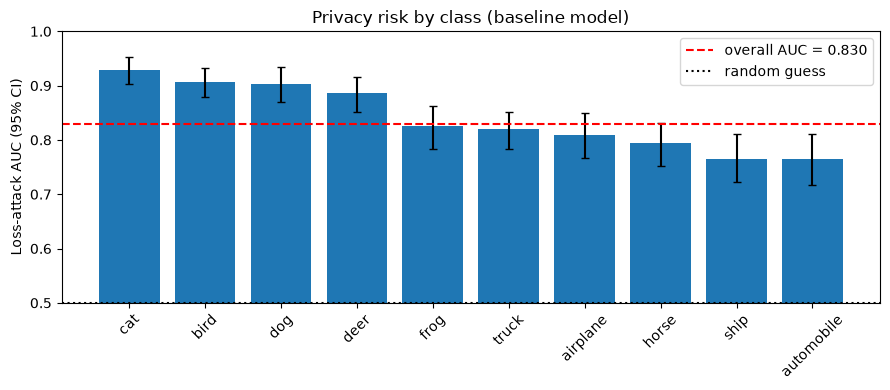

In [44]:
rows = []
for c in range(10):
    mm, nn_ = ym_np == c, yn_np == c
    lo, hi = boot_ci(score_m[mm], score_n[nn_])
    rows.append({'class': class_names[c], 'auc': auc_scores(score_m[mm], score_n[nn_]), 'ci_lo': lo, 'ci_hi': hi,
                 'member_acc': sig_mem['correct'][mm].mean(), 'nonmember_acc': sig_non['correct'][nn_].mean()})
pc = pd.DataFrame(rows)
pc['class_gap'] = pc['member_acc'] - pc['nonmember_acc']
pc = pc.sort_values('auc', ascending=False).reset_index(drop=True)
display(pc.round(3))

overall = auc_scores(score_m, score_n)
plt.figure(figsize=(9, 4))
plt.bar(pc['class'], pc['auc'], yerr=[pc['auc'] - pc['ci_lo'], pc['ci_hi'] - pc['auc']], capsize=3)
plt.axhline(overall, color='r', ls='--', label=f'overall AUC = {overall:.3f}')
plt.axhline(0.5, color='k', ls=':', label='random guess')
plt.ylim(0.5, 1.0); plt.xticks(rotation=45); plt.ylabel('Loss-attack AUC (95% CI)')
plt.title('Privacy risk by class (baseline model)'); plt.legend(); plt.tight_layout(); plt.show()

### 9.3 Is the difference between classes real, and why does it happen?
**Permutation test:** the observed class spread is 0.163 against 0.062 expected by chance (p = 0.0033), so class-dependent vulnerability is real.

**Explanation:** class AUC is almost perfectly correlated with the model's accuracy on unseen images of that class (Spearman rho = -0.98) and with the class generalization gap (rho = 0.98). The classes the model generalizes to worst (cat, bird, dog) are the classes whose training members it exposes most. So the disparity is largely **disparate generalization**: the same cause that drives overall leakage in Section 7 also drives the differences between classes.

**Caveat.** This is a correlation over only 10 classes. It is the most likely explanation, and the hard-sample analysis below gives a second, independent test.

In [45]:
obs, null_mean, p = spread_test(score_m, score_n, ym_np, yn_np)
print(f'Observed spread (max - min class AUC): {obs:.3f}')
print(f'Expected spread by chance alone      : {null_mean:.3f}')
print(f'Permutation p-value                  : {p:.4f}')

from scipy.stats import spearmanr
r1, p1 = spearmanr(pc['auc'], pc['class_gap'])
r2, p2 = spearmanr(pc['auc'], pc['nonmember_acc'])
print(f'Class AUC vs class generalization gap : rho={r1:.2f} (p={p1:.3f})')
print(f'Class AUC vs class unseen-data accuracy: rho={r2:.2f} (p={p2:.3f})')

Observed spread (max - min class AUC): 0.163
Expected spread by chance alone      : 0.062
Permutation p-value                  : 0.0033
Class AUC vs class generalization gap : rho=0.98 (p=0.000)
Class AUC vs class unseen-data accuracy: rho=-0.98 (p=0.000)


### 9.4 Hard vs. easy samples
Does leakage also depend on how *difficult an individual image is*, independent of its class?

**Design choice.** We measure difficulty with the **shadow model**, which never saw these images. If we used the target's own loss, "hard" would partly mean "the target failed to memorize it", which is circular. All samples (members and non-members) are split into five difficulty levels by the shadow model's loss, and the attack AUC is computed within each level.

**How to read it.** A rising curve means the hardest samples are the most exposed, which is the privacy concern for outliers. A flat curve means class difficulty, not sample difficulty, explains the disparity. Either outcome is a valid finding; report whatever your numbers show and include the confidence intervals.

,hardness,n_mem,n_non,auc,ci_lo,ci_hi,target_acc_on_nonmembers
0,easiest,511,489,0.688,0.658,0.721,0.853
1,easy,485,515,0.814,0.787,0.840,0.654
2,medium,513,487,0.879,0.853,0.901,0.509
3,hard,504,496,0.916,0.897,0.934,0.385
4,hardest,487,513,0.955,0.939,0.971,0.214


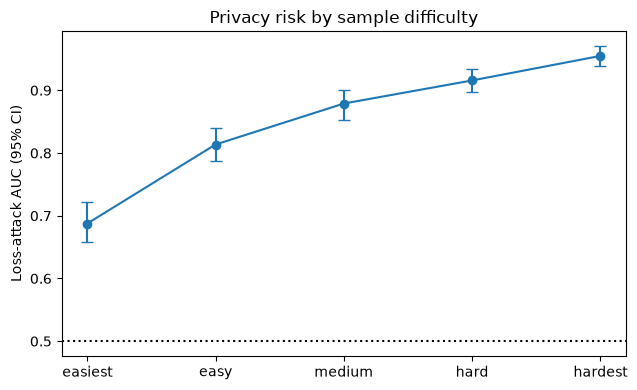

In [46]:
ref_m = get_signals(shadow, X_mem, y_mem)['loss']      # difficulty according to the shadow model
ref_n = get_signals(shadow, X_non, y_non)['loss']
edges = np.quantile(np.r_[ref_m, ref_n], np.linspace(0, 1, 6))
bin_m = np.clip(np.digitize(ref_m, edges[1:-1]), 0, 4)
bin_n = np.clip(np.digitize(ref_n, edges[1:-1]), 0, 4)

names_h = ['easiest', 'easy', 'medium', 'hard', 'hardest']
rows = []
for b in range(5):
    sm_b, sn_b = score_m[bin_m == b], score_n[bin_n == b]
    lo, hi = boot_ci(sm_b, sn_b)
    rows.append({'hardness': names_h[b], 'n_mem': len(sm_b), 'n_non': len(sn_b),
                 'auc': auc_scores(sm_b, sn_b), 'ci_lo': lo, 'ci_hi': hi,
                 'target_acc_on_nonmembers': sig_non['correct'][bin_n == b].mean()})
hd = pd.DataFrame(rows)
display(hd.round(3))

plt.figure(figsize=(6.5, 4))
plt.errorbar(hd['hardness'], hd['auc'], yerr=[hd['auc'] - hd['ci_lo'], hd['ci_hi'] - hd['auc']], fmt='o-', capsize=4)
plt.axhline(0.5, color='k', ls=':'); plt.ylabel('Loss-attack AUC (95% CI)')
plt.title('Privacy risk by sample difficulty'); plt.tight_layout(); plt.show()

### 9.5 Do the defenses protect every class equally?
For each trained model we compute the per-class AUC and run the same permutation test. The **heatmap** shows the per-class risk (red = high, green = near random).

| Defense | Mean class AUC | Spread vs. chance | p | Reading |
|---|---|---|---|---|
| Baseline | 0.840 | 0.163 vs 0.061 | 0.005 | unequal |
| Early stop | 0.568 | 0.071 vs 0.079 | 0.642 | no detectable disparity |
| **Dropout + weight decay** | 0.794 | **0.190** vs 0.067 | 0.005 | **average improves, inequality does not** |
| Label smoothing | 0.912 | 0.134 vs 0.050 | 0.005 | everyone highly exposed (cat 0.975) |
| Augmentation | 0.659 | 0.115 vs 0.076 | 0.055 | borderline |
| Aug + dropout + WD | 0.578 | 0.087 vs 0.078 | 0.333 | no detectable disparity |
| DP-SGD (eps 8 / 2) | 0.521 / 0.517 | at or below chance | 0.94 / 0.97 | no detectable disparity |

**Main message.** Dropout + weight decay lowers the *average* attack success but leaves the same classes (bird, cat) exposed, so an average-only evaluation would call it a partial success and miss the disparity. That is a concrete reason to report per-group risk and not just overall AUC.

**Caveats.** (i) p = 0.005 is the smallest value this 200-shuffle test can produce, so the "significant" rows cannot be ranked by p-value. (ii) One model per defense, no error bars: dropout + WD's spread (0.190) is *not* proven larger than the baseline's (0.163); say "did not reduce the disparity". (iii) "No detectable disparity" for early stopping, the combined defense and DP-SGD may partly be a floor effect: when the average AUC is near 0.5 there is little leakage left to be unequal about. It does not prove those defenses are fair.

,defense,overall_auc,mean_class_auc,worst_class,worst_auc,best_auc,spread,chance_spread,p_value
0,Baseline,0.830,0.840,cat,0.928,0.765,0.163,0.061,0.005
1,Early stop,0.563,0.568,bird,0.605,0.534,0.071,0.079,0.642
2,Dropout + WD,0.770,0.794,bird,0.886,0.695,0.190,0.067,0.005
3,Label smoothing,0.913,0.912,cat,0.975,0.841,0.134,0.050,0.005
4,Augmentation,0.644,0.659,bird,0.726,0.611,0.115,0.076,0.055
5,Aug + drop + WD,0.567,0.578,frog,0.627,0.540,0.087,0.078,0.333
6,DP-SGD eps=8,0.521,0.521,bird,0.552,0.501,0.051,0.079,0.935
7,DP-SGD eps=2,0.517,0.517,cat,0.537,0.494,0.043,0.080,0.965


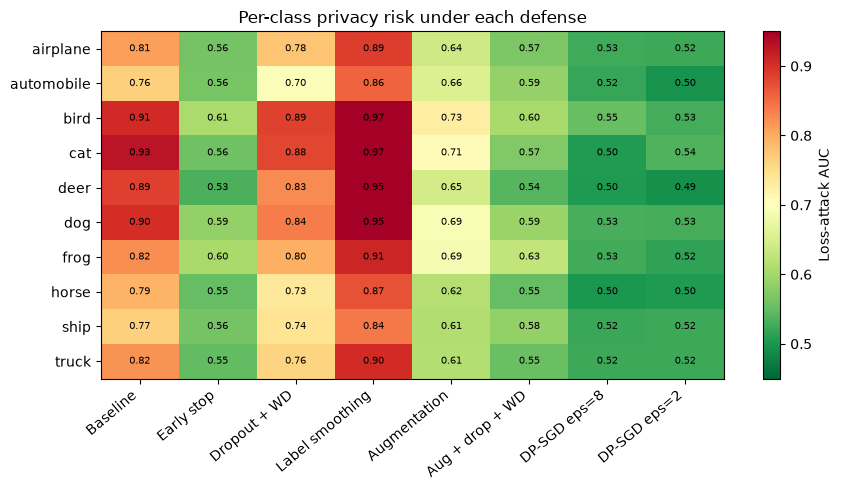

In [47]:
variants = {  # label: (cache key, dropout used in training)
    'Baseline':        (None,      0.0),
    'Early stop':      ('early',   0.0),
    'Dropout + WD':    ('wd_drop', 0.5),
    'Label smoothing': ('smooth',  0.0),
    'Augmentation':    ('augment', 0.0),
    'Aug + drop + WD': ('combo',   0.5),
    'DP-SGD eps=8':    ('dp8',     0.0),
    'DP-SGD eps=2':    ('dp2',     0.0),
}

rows, heat = [], {}
for label, (key, dr) in variants.items():
    if key is None:
        mdl = target
    else:
        mdl = SmallCNN(dr).to(device)
        if not load_model_if_exists(mdl, f'def_{key}_{tag}'):
            print('missing saved model, skipping:', label); continue
    s_m, s_n = get_signals(mdl, X_mem, y_mem), get_signals(mdl, X_non, y_non)
    sc_m, sc_n = -s_m['loss'], -s_n['loss']
    aucs = class_aucs(sc_m, sc_n, ym_np, yn_np)
    obs, null_mean, p = spread_test(sc_m, sc_n, ym_np, yn_np, B=200)
    heat[label] = aucs
    rows.append({'defense': label, 'overall_auc': auc_scores(sc_m, sc_n), 'mean_class_auc': aucs.mean(),
                 'worst_class': class_names[aucs.argmax()], 'worst_auc': aucs.max(),
                 'best_auc': aucs.min(), 'spread': obs, 'chance_spread': null_mean, 'p_value': p})
dis = pd.DataFrame(rows)
display(dis.round(3))

H = pd.DataFrame(heat, index=class_names)
plt.figure(figsize=(9, 5))
plt.imshow(H.values, cmap='RdYlGn_r', vmin=0.45, vmax=0.95, aspect='auto')
plt.colorbar(label='Loss-attack AUC')
plt.xticks(range(H.shape[1]), H.columns, rotation=40, ha='right'); plt.yticks(range(10), class_names)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        plt.text(j, i, f'{H.values[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.title('Per-class privacy risk under each defense'); plt.tight_layout(); plt.show()

save_obj({'per_class': pc, 'hardness': hd, 'defenses': dis}, f'disparate_{tag}')

---
# 10. Results at a glance

The next cell builds the headline table **directly from the variables of this run** (nothing is hard-coded), prints it, and saves it to `artifacts/headline_results.csv` for your report.

In [48]:
from scipy.stats import pearsonr

def pm(df, row, col):                       # "mean ± std" text for one cell of an aggregated table
    return f"{df.loc[row, (col, 'mean')]:.3f} ± {df.loc[row, (col, 'std')]:.3f}"

first_ep, last_ep = agg.index.min(), agg.index.max()
small_n, large_n  = sz.index.min(), sz.index.max()
base_row = dis[dis.defense == 'Baseline'].iloc[0]
top, bottom = pc.iloc[0], pc.iloc[-1]
dp8 = res_df.set_index('setting').loc['DP-SGD (eps=8)']

headline = pd.DataFrame([
    ('RQ1  Simple threshold attack works',
     f"loss attack AUC {res_loss['auc']:.3f}, confidence attack AUC {res_conf['auc']:.3f} (random = 0.5)"),
    ('RQ1  Realistic shadow-model attack is stronger at low FPR',
     f"AUC {res_shadow['auc']:.3f}; TPR@1%FPR {res_shadow['tpr@1%fpr']:.3f} vs {res_loss['tpr@1%fpr']:.3f} for the loss threshold"),
    ('RQ2  Leakage grows with overfitting',
     f"AUC {agg.loc[first_ep, ('margin_auc', 'mean')]:.3f} at epoch {first_ep} -> {agg.loc[last_ep, ('margin_auc', 'mean')]:.3f} at epoch {last_ep}; "
     f"gap-AUC r = {pearsonr(ms_df['gap'], ms_df['margin_auc'])[0]:.3f}"),
    ('RQ2  Less data, more leakage',
     f"AUC {sz.loc[small_n, ('margin_auc', 'mean')]:.3f} with {small_n} images vs {sz.loc[large_n, ('margin_auc', 'mean')]:.3f} with {large_n}"),
    ('RQ3  Best practical defense',
     f"augmentation + dropout + weight decay: accuracy {pm(agg_def, 'Aug + dropout + wd', 'test_acc')}, "
     f"attack AUC {pm(agg_def, 'Aug + dropout + wd', 'worst_case_auc')} (baseline: {pm(agg_def, 'Baseline (30 ep)', 'test_acc')}, {pm(agg_def, 'Baseline (30 ep)', 'worst_case_auc')})"),
    ('RQ3  Label smoothing backfires',
     f"attack AUC {pm(agg_def, 'Label smoothing', 'worst_case_auc')} vs baseline {pm(agg_def, 'Baseline (30 ep)', 'worst_case_auc')}"),
    ('RQ3  DP-SGD (eps = 8, untuned)',
     f"attack AUC {dp8['worst_case_auc']:.3f} but test accuracy only {dp8['test_acc']:.3f}"),
    ('RQ4  Privacy risk is unequal across classes',
     f"class-AUC spread {base_row['spread']:.3f} vs {base_row['chance_spread']:.3f} by chance (p = {base_row['p_value']:.3f}); "
     f"most exposed {top['class']} ({top['auc']:.3f}), least exposed {bottom['class']} ({bottom['auc']:.3f})"),
    ('RQ4  Risk follows how badly the model generalizes to the class',
     f"Spearman rho(class AUC, accuracy on unseen images) = {r2:.2f}"),
], columns=['finding', 'evidence'])

pd.set_option('display.max_colwidth', None)
display(headline)
headline.to_csv('artifacts/headline_results.csv', index=False)

,finding,evidence
0,RQ1 Simple threshold attack works,"loss attack AUC 0.830, confidence attack AUC 0.777 (random = 0.5)"
1,RQ1 Realistic shadow-model attack is stronger at low FPR,AUC 0.861; TPR@1%FPR 0.051 vs 0.017 for the loss threshold
2,RQ2 Leakage grows with overfitting,AUC 0.522 at epoch 1 -> 0.836 at epoch 30; gap-AUC r = 0.996
3,"RQ2 Less data, more leakage",AUC 0.900 with 500 images vs 0.780 with 5000
4,RQ3 Best practical defense,"augmentation + dropout + weight decay: accuracy 0.565 ± 0.014, attack AUC 0.572 ± 0.009 (baseline: 0.529 ± 0.010, 0.833 ± 0.014)"
5,RQ3 Label smoothing backfires,attack AUC 0.914 ± 0.005 vs baseline 0.833 ± 0.014
6,"RQ3 DP-SGD (eps = 8, untuned)",attack AUC 0.521 but test accuracy only 0.286
7,RQ4 Privacy risk is unequal across classes,"class-AUC spread 0.163 vs 0.061 by chance (p = 0.005); most exposed cat (0.928), least exposed automobile (0.765)"
8,RQ4 Risk follows how badly the model generalizes to the class,"Spearman rho(class AUC, accuracy on unseen images) = -0.98"
